# Exploring Message Passing Schemes

The model in this notebook is declared in the
[Generalized Notation Notation](https://github.com/ActiveInferenceInstitute/Generalized_Notation_Notation)
document `specs/normal_vmp.gnn.md`: that document is the single source of truth
for the priors, the data statistics, the observation count, the iteration count,
and the seed. The next cell reads those declarations with `src/spec_reader.jl`.

In [1]:
using RxInfer, Distributions, Random

include(joinpath(@__DIR__, "..", "src", "spec_reader.jl"))

spec_summary (generic function with 2 methods)

## Variational Message Passing

[RxInfer documentation on variational inference](https://docs.rxinfer.com/stable/concepts/variational-inference/)

This notebook estimates the mean and precision of data generated from a Normal distribution. Variational message passing (VMP) updates approximate posterior marginals through local factor-graph computations.

The model, its priors, and the generating values used below are read from `specs/normal_vmp.gnn.md`, so the specification and the code cannot drift apart.

### What to look for

The model places a Normal prior on the unknown mean `m` and a Gamma prior on the unknown precision `w`, then observes the declared number of Normal samples. The `MeanField()` constraint makes the approximation factorize as `q(m, w) = q(m) q(w)`, so the two marginals are updated one after the other and the updates are iterated. The two plots show posterior marginals after selected iterations; the vertical lines mark the generating values declared in the specification. The mean plot displays iterations 1, 2, and 10, while the precision plot displays 2, 3, and 10.

In [2]:
# Every parameter below is read from specs/normal_vmp.gnn.md.
const PARAMETERS = spec_parameters()
const vmp_iterations = PARAMETERS.vmp_iterations

rng = MersenneTwister(PARAMETERS.seed)

data = rand(
    rng,
    Normal(PARAMETERS.data_mean, sqrt(inv(PARAMETERS.data_precision))),
    PARAMETERS.n_observations,
)

println(spec_summary())
println()
println("sample mean:      ", mean(data))
println("sample precision: ", 1 / var(data))

model_name=ActiveInferenceImplementations Mean-Field VMP Normal Estimation
m_prior_mean=0.0
m_prior_variance=10.0
w_prior_shape=0.1
w_prior_rate=10.0
data_mean=-4.0
data_precision=0.2
n_observations=100
vmp_iterations=10
seed=1234



sample mean:      -4.325602860513428
sample precision: 0.15001687928186408


### Model specification

`m` and `w` are latent: the mean and the precision of the Normal likelihood. The
observations are conditionally independent given them.

In [3]:
@model function normal_estimation(y, m_μ, m_v, w_α, w_β)
    m ~ NormalMeanVariance(m_μ, m_v)
    # The Gamma prior is parameterized by shape and rate. Positional arguments are
    # (shape, scale) instead, so the keyword form is the unambiguous one.
    w ~ Gamma(shape = w_α, rate = w_β)

    for i in eachindex(y)
        y[i] ~ NormalMeanPrecision(m, w)
    end
end

### Constraints and initialization

`MeanField()` declares the factorisation `q(m, w) = q(m) q(w)` that the specification states, and the marginals are initialized vaguely so the first iteration starts from a nearly flat approximation.

In [4]:
constraints = MeanField()

initialization = @initialization(begin
    q(m) = vague(NormalMeanVariance)
    q(w) = vague(GammaShapeRate)
end)
nothing

### Inference execution

`infer` runs the declared number of iterations and records the marginal of every latent variable after each iteration, together with the free energy of the approximation.

In [5]:
result = infer(
    model = normal_estimation(
        m_μ = PARAMETERS.m_prior_mean,
        m_v = PARAMETERS.m_prior_variance,
        w_α = PARAMETERS.w_prior_shape,
        w_β = PARAMETERS.w_prior_rate,
    ),
    data           = (y = data, ),
    constraints    = constraints,
    initialization = initialization,
    iterations     = vmp_iterations,
    free_energy    = true,
)

# One marginal per iteration: `m_marginals[i]` is q(m) after iteration i.
m_marginals = result.posteriors[:m]
w_marginals = result.posteriors[:w]

10-element Vector{GammaShapeRate{Float64}}:
 GammaShapeRate{Float64}(a=50.1, b=5.000000000127549e13)
 GammaShapeRate{Float64}(a=50.1, b=1775.504872726381)
 GammaShapeRate{Float64}(a=50.1, b=358.1719320233538)
 GammaShapeRate{Float64}(a=50.1, b=343.55920555997625)
 GammaShapeRate{Float64}(a=50.1, b=343.4116485728032)
 GammaShapeRate{Float64}(a=50.1, b=343.41015891950127)
 GammaShapeRate{Float64}(a=50.1, b=343.4101438808259)
 GammaShapeRate{Float64}(a=50.1, b=343.4101437290041)
 GammaShapeRate{Float64}(a=50.1, b=343.41014372747134)
 GammaShapeRate{Float64}(a=50.1, b=343.4101437274558)

### Convergence

The free energy is the quantity the iterations minimize. It falls quickly over the
first few iterations and then flattens out, which is the usual sign that the
approximation has converged.

In [6]:
println("marginals recorded: ", length(m_marginals), " (one per iteration)")
println("free energy: ", round.(result.free_energy; digits = 3))
println()
println("mean of q(m) after the last iteration:      ", mean(m_marginals[end]))
println("mean of q(w) after the last iteration:      ", mean(w_marginals[end]))
println("sample mean:                                ", mean(data))
println("sample precision:                           ", 1 / var(data))

marginals recorded: 10 (one per iteration)
free energy: 

[1479.167, 285.884, 244.455, 244.412, 244.412, 244.412, 244.412, 244.412, 244.412, 244.412]

mean of q(m) after the last iteration:      -4.296154893062295
mean of q(w) after the last iteration:      0.1458896917144107
sample mean:                                -4.325602860513428
sample precision:                           0.15001687928186408


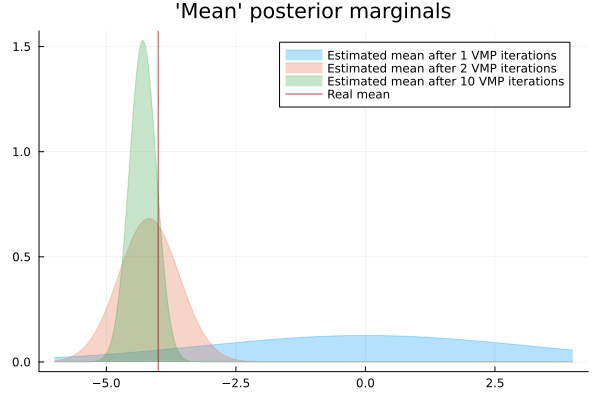

In [7]:
using Plots

p1    = plot(title = "'Mean' posterior marginals")
grid1 = -6.0:0.01:4.0

for iter in [ 1, 2, 10 ]

    e_pdf = (x) -> pdf(m_marginals[iter], x)

    plot!(p1, grid1, e_pdf, fill = true, opacity = 0.3, label = "Estimated mean after $iter VMP iterations")

end

plot!(p1, [ PARAMETERS.data_mean ], seriestype = :vline, label = "Real mean", color = :red4, opacity = 0.7)

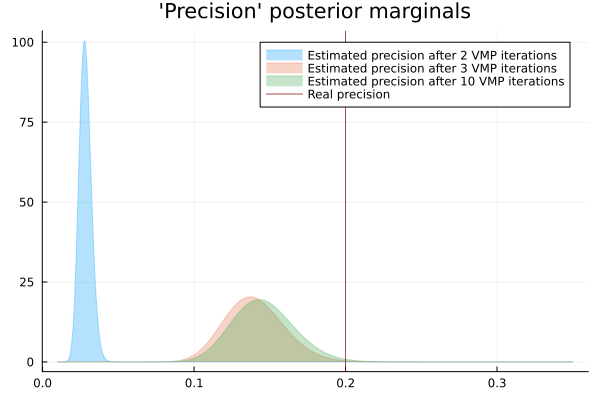

In [8]:
p2    = plot(title = "'Precision' posterior marginals")
grid2 = 0.01:0.001:0.35

for iter in [ 2, 3, 10 ]

    e_pdf = (x) -> pdf(w_marginals[iter], x)

    plot!(p2, grid2, e_pdf, fill = true, opacity = 0.3, label = "Estimated precision after $iter VMP iterations")

end

plot!(p2, [ PARAMETERS.data_precision ], seriestype = :vline, label = "Real precision", color = :red4, opacity = 0.7)

### Where to go next

The individual updates of these marginals are messages as well: `@call_message_update_rule` from the first notebook evaluates a single message update rule, and [the RxInfer manual](https://docs.rxinfer.com/stable/manuals/inference/overview/) describes the schedules `infer` can run.

`specs/normal_vmp.gnn.md` is validated in CI against the GNN revision pinned in `specs/gnn-pin.json` (GNN v5.0.3, commit `8f293d9ba`), and `test/runtests.jl` checks that the notebook, the specification, and the reported posteriors agree.